[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nattaponm/Teach_stormTracks_KKN_May2024_HID_doppler/blob/main/prep/P1_cappi_all_days.ipynb)


# P1 — pseudo-CAPPI 2 km ทุกวัน ทุก volume

**สำหรับผู้ดูแลข้อมูล** — ต่อจาก P0 (อ่าน UF จาก Drive ส่วนตัว)

ต่อ 1 volume: อ่าน UF (ตรวจชนิดการบีบอัดจากไบต์แรก) → gentle base-QC → **pseudo-CAPPI 2 km เหนือระดับเรดาร์** และ **Z สูงสุดในคอลัมน์** บนกริด 1 km 481 × 481 → สถิติ echo

**อัลกอริทึมและรูปแบบไฟล์เดียวกับ repo `Teach_Pysteps_KKN_summerStorm` ทุกค่า** ไฟล์จึงอ่านด้วย `utils.data_io.load_pcappi` (ของ repo3) และใช้กับ pysteps ได้ทันที เซลล์ท้าย notebook ตรวจเทียบกับไฟล์ของ repo pysteps (ทดสอบแล้วต่างกัน 0.00 dBZ)

**Runtime:** CPU + High-RAM (ประมาณ 0.4 วินาที/volume/core) — รันซ้ำได้ ข้ามวันที่ทำแล้ว

| ผลลัพธ์ใน `KKN_derived_v1/` | เนื้อหา |
|---|---|
| `cappi/KKN_YYYYMMDD_cappi_15min.nc` | pseudo-CAPPI + Z คอลัมน์ 96 ช่อง/วัน (~3–4 MB) |
| `stats/KKN_YYYYMMDD_p1_stats.csv`, `volume_stats_p1.csv` | สถิติ echo ต่อ volume (ทั้งเดือนคัดลอกเข้า `data/derived/` ด้วย) |

In [8]:
# @title ⚙️ เตรียมสภาพแวดล้อม (รันก่อนเสมอ)
import os, sys, subprocess
REPO = "Teach_stormTracks_KKN_May2024_HID_doppler"
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.isdir(f"/content/{REPO}"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", f"https://github.com/nattaponm/{REPO}.git", f"/content/{REPO}"], check=True)
    else:
        subprocess.run(["git", "-C", f"/content/{REPO}", "pull", "-q"])
    os.chdir(f"/content/{REPO}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt", "arm_pyart"], check=True)
elif os.path.basename(os.getcwd()) in ("notebooks", "prep"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("โฟลเดอร์ทำงาน:", os.getcwd(), "| CPU", os.cpu_count(), "core")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
โฟลเดอร์ทำงาน: /content/Teach_stormTracks_KKN_May2024_HID_doppler | CPU 8 core


In [9]:
import json, time, shutil, warnings
from pathlib import Path
from functools import partial
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mproc
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings("ignore")

from utils.config import load_settings, repo_path
from utils import maps as M
s = load_settings()
M.setup_style()
OUT_ROOT = Path(os.environ.get("KKN_OUT_ROOT", s["radar_data"]["drive_derived_root"]))
N_WORKERS = os.cpu_count()
CTX = mproc.get_context("fork")

from utils import radar_inventory as RI, radar_prep as RP, derived_io as DIO
RAW_ROOT = Path(os.environ.get("KKN_RAW_ROOT", s["radar_data"]["drive_raw_root"]))
assert RAW_ROOT.exists(), f"ไม่พบ {RAW_ROOT} — แก้ drive_raw_root ใน config/settings.yaml"
CAPPI_DIR, STATS_DIR = OUT_ROOT / "cappi", OUT_ROOT / "stats"
for d in (CAPPI_DIR, STATS_DIR):
    d.mkdir(parents=True, exist_ok=True)

#DAYS = ["20240503"]     # ← รอบแรก: 3 พ.ค. เพื่อจับเวลาและตรวจเทียบ | ทั้งเดือน: DAYS = None
DAYS = None     # ← รอบแรก: 3 พ.ค. เพื่อจับเวลาและตรวจเทียบ | ทั้งเดือน: DAYS = None
OVERWRITE = False

In [10]:
files = RI.assign_slots(RI.list_files(RAW_ROOT, s, "2405"), s)
files = files[files["status"].isin(["ok", "offset", "small"])].copy()   # ไฟล์เล็กผิดปกติก็ลองอ่าน ถ้าเสียจะบันทึกว่า failed
files["day"] = files["slot_utc"].dt.strftime("%Y%m%d")
all_days = sorted(files["day"].unique())
days = all_days if DAYS is None else [d for d in DAYS if d in all_days]
print(f"ไฟล์ที่ใช้ได้ {len(files)} ใน {len(all_days)} วัน | รอบนี้ {len(days)} วัน")

ไฟล์ที่ใช้ได้ 2962 ใน 31 วัน | รอบนี้ 31 วัน


In [11]:
def process_day(day):
    out_nc, out_csv = CAPPI_DIR / f"KKN_{day}_cappi_15min.nc", STATS_DIR / f"KKN_{day}_p1_stats.csv"
    if out_nc.exists() and out_csv.exists() and not OVERWRITE:
        return "skip", 0.0
    t0 = time.time()
    f = files[files["day"] == day].sort_values("slot_utc")
    slots = pd.date_range(pd.Timestamp(day), periods=96, freq="15min")
    n = len(RP.grid_axes()[0])
    dbz = np.full((96, n, n), np.nan, np.float32); zcol = dbz.copy()
    avail = np.zeros(96, np.uint8); scan = [pd.NaT] * 96; vny = np.full(96, np.nan, np.float32)
    rows, src_h, site = [], None, None
    with ProcessPoolExecutor(N_WORKERS, mp_context=CTX) as ex:
        for row, d, zc, sh, st in ex.map(RP.p1_volume, f["path"], f["slot_utc"]):
            rows.append(row)
            if d is None:
                continue
            i = int((row["slot_utc"] - slots[0]) / pd.Timedelta("15min"))
            dbz[i], zcol[i], avail[i], scan[i], vny[i] = d, zc, 1, row["scan_start"], row["nyquist"]
            if src_h is None:
                src_h, site = sh, st
    stats = pd.DataFrame(rows).sort_values("slot_utc")
    stats.to_csv(out_csv, index=False)
    if site is not None:
        DIO.write_cappi_day(out_nc, slots, avail, dbz, zcol, src_h, site, scan, vny)
    return f"{int(avail.sum())}/96 ok, {int((stats['status'] != 'ok').sum())} failed, {out_nc.stat().st_size / 1e6:.1f} MB", time.time() - t0

t_all = time.time()
for k, day in enumerate(days, 1):
    msg, dt = process_day(day)
    n = int((files["day"] == day).sum())
    print(f"[{k:2d}/{len(days)}] {day}: {msg}" + (f" | {dt / 60:.1f} นาที ({dt / max(n, 1):.2f} วินาที/volume)" if dt else ""))
print(f"รวม {(time.time() - t_all) / 60:.1f} นาที")


## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly supported
## by the U.S. Department of Energy Office of Science as part of
## the Atmospheric Radiation Measurement (ARM) User Facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119

## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly supported
## by the U.S. Department of Energy Office of Science as part of
## the Atmospheric Radiation Measurement (ARM) User Facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119

## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly supported
## by the U.S. Department of 

In [12]:
stats = pd.concat([pd.read_csv(p, parse_dates=["slot_utc", "scan_start"]) for p in sorted(STATS_DIR.glob("KKN_*_p1_stats.csv"))],
                  ignore_index=True)
for p in (OUT_ROOT / "volume_stats_p1.csv", repo_path("data", "derived", "volume_stats_p1.csv")):
    p.parent.mkdir(parents=True, exist_ok=True); stats.to_csv(p, index=False)
print("สถานะ:", stats["status"].value_counts().to_dict())
if (stats["status"] != "ok").any():
    display(stats.loc[stats["status"] != "ok", ["slot_utc", "error"]].head(10))

สถานะ: {'ok': 2962}


## ตรวจเทียบกับไฟล์ของ repo pysteps (3 พ.ค.) — ควรต่างไม่เกิน 0.05 dBZ

In [13]:
import urllib.request
mine = CAPPI_DIR / "KKN_20240503_cappi_15min.nc"
if mine.exists():
    ref = Path("ref_pcappi.nc")
    urllib.request.urlretrieve("https://raw.githubusercontent.com/nattaponm/Teach_Pysteps_KKN_summerStorm/main/"
                               "data/KKN_20240503/KKN_20240503_pcappi2km_dbz.nc", ref)
    a, b = xr.open_dataset(mine)["reflectivity"], xr.open_dataset(ref)["reflectivity"]
    t = np.intersect1d(a.time.values, b.time.values)
    A, Bv = a.sel(time=t).values, b.sel(time=t).values
    ok = np.isfinite(A) & np.isfinite(Bv)
    print(f"เวลาร่วม {len(t)} | ต่างสูงสุด {np.nanmax(np.abs(A[ok] - Bv[ok])):.2f} dBZ | "
          f"pixel ที่ NaN ไม่ตรงกัน {int((np.isfinite(A) != np.isfinite(Bv)).sum())}")

เวลาร่วม 96 | ต่างสูงสุด 0.00 dBZ | pixel ที่ NaN ไม่ตรงกัน 0


## ปฏิทินพายุ: พื้นที่ pseudo-CAPPI ≥ 35 dBZ ทุก 15 นาทีทั้งเดือน

บันทึกรูป → /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/0data/1radar/KKN_derived_v1/figures/p1_storm_calendar.png / .pdf


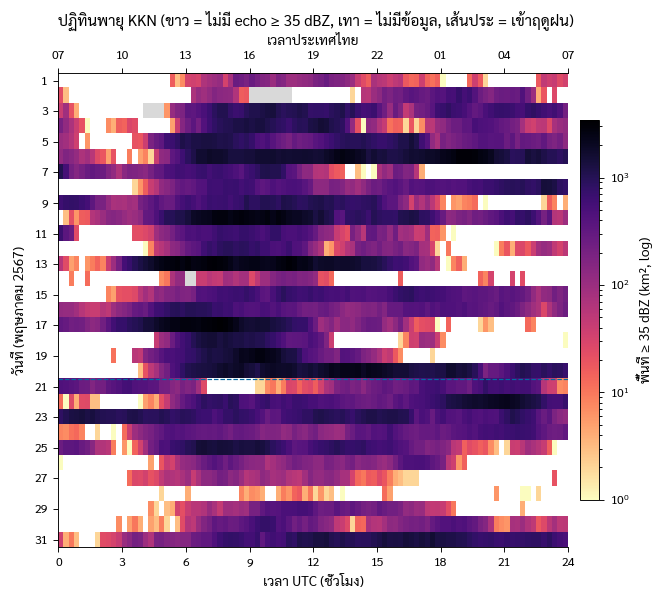

In [14]:
from matplotlib.colors import LogNorm
st = stats[stats["status"] == "ok"].copy()
st["day"] = st["slot_utc"].dt.day; st["slot"] = st["slot_utc"].dt.hour * 4 + st["slot_utc"].dt.minute // 15
grid = np.full((31, 96), np.nan)
grid[st["day"] - 1, st["slot"]] = np.where(st["area_ge35_km2"] < 1, 0.5, st["area_ge35_km2"])
cmap = plt.get_cmap("magma_r").copy(); cmap.set_under("white")
fig, ax = plt.subplots(figsize=(7.2, 5.6))
im = ax.imshow(grid, aspect="auto", cmap=cmap, norm=LogNorm(1, max(np.nanmax(grid), 10)), extent=(0, 24, 31.5, 0.5),
               interpolation="nearest")
ax.set_facecolor("0.85")
ax.set_xticks(range(0, 25, 3)); ax.set_yticks(range(1, 32, 2))
ax.set_xlabel("เวลา UTC (ชั่วโมง)"); ax.set_ylabel("วันที่ (พฤษภาคม 2567)")
top = ax.secondary_xaxis("top"); top.set_xticks(range(0, 25, 3), [f"{(h + 7) % 24:02d}" for h in range(0, 25, 3)])
top.set_xlabel("เวลาประเทศไทย")
ax.axhline(20.5, color="#0369a1", lw=0.8, ls="--")
fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02, label="พื้นที่ ≥ 35 dBZ (km², log)")
ax.set_title("ปฏิทินพายุ KKN (ขาว = ไม่มี echo ≥ 35 dBZ, เทา = ไม่มีข้อมูล, เส้นประ = เข้าฤดูฝน)", loc="left")
M.savefig(fig, "p1_storm_calendar", outdir=OUT_ROOT / "figures")
plt.show()

**ขั้นต่อไป:** เปลี่ยนเป็น `DAYS = None` รันทั้งเดือน แล้วรัน PS (ถ้ายังไม่ได้รัน) และ P2